## Chapter 4: Testing and regularization

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
random.seed(0)

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

#### Defining our dataset

Plotting the polynomial $-x^2+2$ 

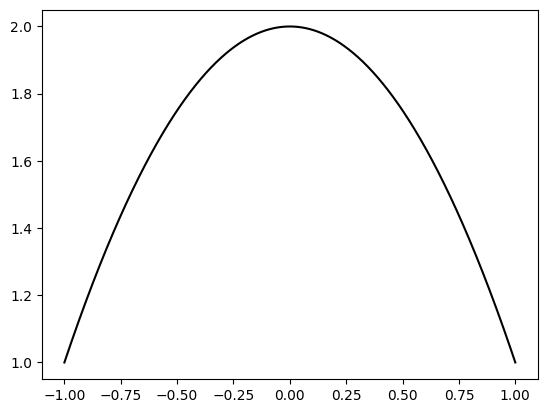

In [2]:
# Our original polynomial is -x^2+2
coefs = [2,0,-1]

def polynomial(coefs, x):
    n = len(coefs)
    return sum([coefs[i]*x**i for i in range(n)])   # 2 + 0x + (-1)x^2

def draw_polynomial(coefs):
    n = len(coefs)
    x = np.linspace(-1, 1, 1000)
    #plt.ylim(0,3)
    plt.plot(x, sum([coefs[i]*x**i for i in range(n)]), linestyle='-', color='black')

draw_polynomial(coefs)

Generating a dataset of 40 points, close to this polynomial

In [3]:
X = []
Y = []

for i in range(40):
    x = random.uniform(-1, 1)
    y = polynomial(coefs, x) + random.gauss(0, 0.1) 
    X.append(x)
    Y.append(y)

**random.gauss(0, 0.1)** generates noise from a Gaussian (normal) distribution with mean 0 and standard deviation 0.1. The noise is usually small, but can be positive or negative.

After the loop, both lists contain 40 values. Together, they represent sample points from the polynomial with added noise.

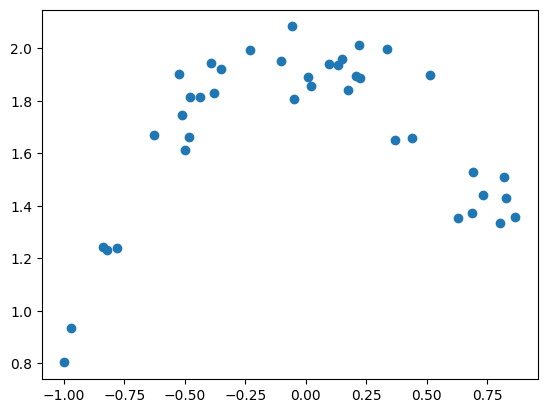

In [4]:
plt.scatter(X, Y)

#### Plotting functions

In [5]:
def plot_polynomial_regression(model, X, Y, degree, X_test=None, Y_test=None):
    """
    Plots the original data points and the polynomial regression curve,
    optionally including test data points.

    Args:
      model: The trained scikit-learn model object.
      X: Input features (list or numpy array).
      Y: Input labels (list or numpy array).
      degree: The degree of the polynomial used for training.
      X_test: Optional test set features (list or numpy array).
      Y_test: Optional test set labels (list or numpy array).
    """
    X = np.array(X).reshape(-1, 1)
    Y = np.array(Y)

    # Generate predicted values for plotting the curve
    X_plot = np.linspace(np.min(X), np.max(X), 100).reshape(-1, 1)
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_plot_poly = poly.fit_transform(X_plot) # Fit on plot data range

    Y_plot_poly = model.predict(X_plot_poly)

    # Plot the original points
    plt.scatter(X, Y, color='blue', label='Original Data')

    # Plot the polynomial regression curve
    plt.plot(X_plot, Y_plot_poly, color='red', label=f'Polynomial Regression (degree {degree})')

    # Plot test data points if provided
    if X_test is not None and Y_test is not None:
        X_test = np.array(X_test).reshape(-1, 1)
        Y_test = np.array(Y_test)
        plt.scatter(X_test, Y_test, color='orange', marker='^', label='Test Data')


    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title(f'Polynomial Regression (Degree {degree})')
    plt.legend()
    plt.grid(True)

    # Set plot bounds based on X and Y
    plt.xlim(np.min(X), np.max(X))
    plt.ylim(np.min(Y), np.max(Y))

    plt.show()

#### Training a polynomial regression model

Let's plot a polynomial of degree 20 to our dataset. Notice how much it overfits!

In [6]:
def train_polynomial_regression(X, Y, degree, regularization=None, alpha=1.0):
  """
  Trains a polynomial regression model with optional L1 or L2 regularization.

  Args:
    X: Input features (list or numpy array).
    Y: Input labels (list or numpy array).
    degree: The degree of the polynomial.
    regularization: Type of regularization ('L1', 'L2', or None). Defaults to None.
    alpha: Regularization strength (for L1 and L2). Defaults to 1.0.

  Returns:
    A trained scikit-learn model object (LinearRegression, Ridge, or Lasso).
  """

  X = np.array(X).reshape(-1, 1)
  Y = np.array(Y)

  poly = PolynomialFeatures(degree=degree, include_bias=False)
  X_poly = poly.fit_transform(X)

  if regularization == "L1":
    model = Lasso(alpha=alpha)
  elif regularization == "L2":
    model = Ridge(alpha=alpha)
  else:
    model = LinearRegression()

  model.fit(X_poly, Y)

  return model

In [7]:
degree_used = 20
model = train_polynomial_regression(X, Y, degree_used)

_____
##### How the Function Trains a Polynomial Regression Model

`np.array(X).reshape(-1, 1)` converts `X` into a NumPy array and reshapes it into a 2D column, with one input value per row. `Y` is converted to a NumPy array as well.

`PolynomialFeatures` expands each input into polynomial features up to `degree`. For example, with degree 2, an input `x` becomes `x` and `x²`. `include_bias=False` leaves out the constant column.

`X_poly = poly.fit_transform(X)`

* Learns how to create the polynomial features from X, then creates them. 

For example, if X contains $[[2], [3]]$ and degree=2, 

`X_poly` becomes:

$[[2, 4],
 [3, 9]]$

The function then selects a model: Lasso for `"L1"`, Ridge for `"L2"`, or ordinary linear regression otherwise. For Lasso and Ridge, `alpha` sets the regularization strength. Finally, `model.fit(X_poly, Y)` trains the model, and `return model` gives back the trained model.

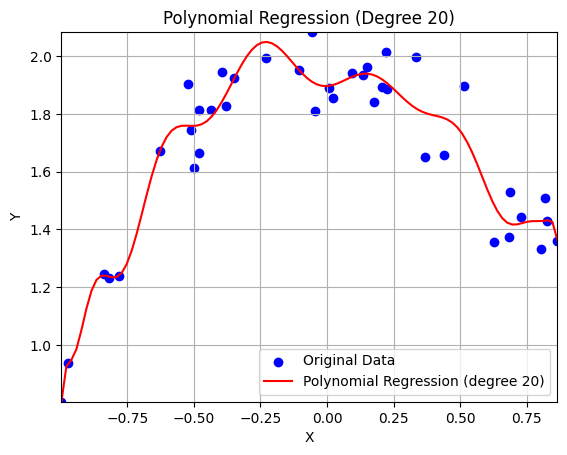

In [8]:
model = train_polynomial_regression(X, Y, degree_used)
plot_polynomial_regression(model, X, Y, degree_used)

#### Splitting data into training and testing

In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

print("Shape of X_train:", np.shape(X_train))
print("Shape of X_test:", np.shape(X_test))
print("Shape of Y_train:", np.shape(Y_train))
print("Shape of Y_test:", np.shape(Y_test))

Shape of X_train: (32,)
Shape of X_test: (8,)
Shape of Y_train: (32,)
Shape of Y_test: (8,)


#### Training a polynomial regression model with no regularization

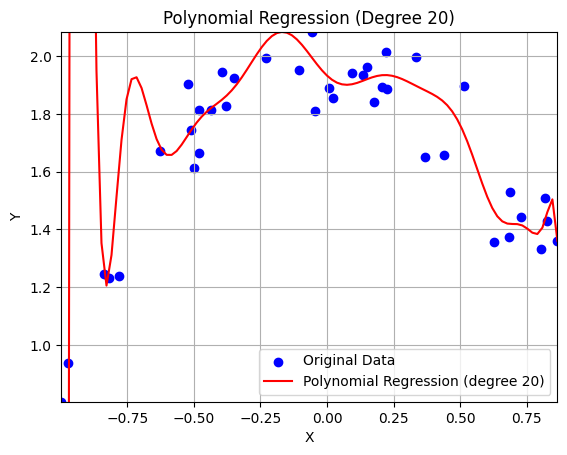

In [10]:
model_no_reg = train_polynomial_regression(X_train, Y_train, degree_used)
plot_polynomial_regression(model_no_reg, X, Y, degree_used)

In [11]:
def evaluate_model(model, X_test, Y_test, degree):
    """
    Evaluates a trained polynomial regression model on test data and returns the RMSE.

    Args:
      model: The trained LinearRegression model object.
      X_test: Test set features (list or numpy array).
      Y_test: Test set labels (list or numpy array).
      degree: The degree of the polynomial used for training.

    Returns:
      The Root Mean Squared Error (RMSE) on the test set.
    """
    X_test = np.array(X_test).reshape(-1, 1)
    Y_test = np.array(Y_test)

    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_test_poly = poly.fit_transform(X_test)

    y_pred = model.predict(X_test_poly)

    rmse = np.sqrt(mean_squared_error(Y_test, y_pred))

    return rmse

In [14]:
square_loss_no_reg = evaluate_model(model_no_reg, X_test, Y_test, degree_used)
print(f"RMSE on the test set (degree {degree_used}): {square_loss_no_reg}")

RMSE on the test set (degree 20): 12.924241969449769


#### Training a polynomial regression model with L1 regularization

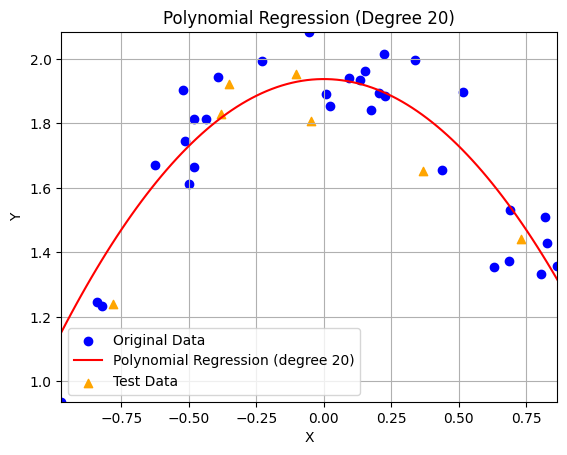

In [15]:
l1_penalty = 0.01

model_L1_reg = train_polynomial_regression(X_train, Y_train, degree_used, "L1", l1_penalty)
plot_polynomial_regression(model_L1_reg, X_train, Y_train, degree_used, X_test, Y_test)

In [16]:
square_loss_L1_reg = evaluate_model(model_L1_reg, X_test, Y_test, degree_used)
print(f"RMSE on the test set (degree {degree_used}): {square_loss_L1_reg}")

RMSE on the test set (degree 20): 0.152772917986916


#### Training a polynomial regression model with L2 regularization

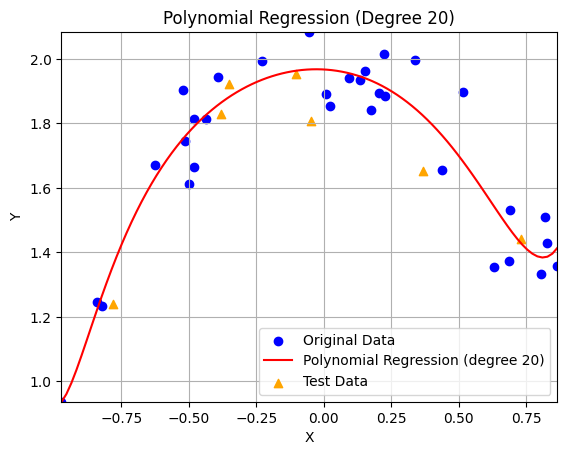

In [17]:
l2_penalty = 0.01
# Train with L2 (Ridge) regularization
model_L2_reg = train_polynomial_regression(X_train, Y_train, degree_used, 'L2', l2_penalty)
plot_polynomial_regression(model_L2_reg, X_train, Y_train, degree_used, X_test, Y_test)

In [18]:
square_loss_L2_reg = evaluate_model(model_L2_reg, X_test, Y_test, degree_used)
print(f"RMSE on the test set (degree {degree_used}): {square_loss_L2_reg}")

RMSE on the test set (degree 20): 0.10370797950325979
